# 01 · Preprocessing — Zhang 2019 Ovarian (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate the two omental sites (Harmony), embed,
remove detached islands, resolve the manifold's transcriptional compartments, and fix a single house
orientation for every downstream UMAP. Zhang et al. (2019) profiled **one treatment-naive high-grade
serous ovarian carcinoma patient (VOA11543)** by **10x**, sampling both the **left (VOA11543L)** and
**right (VOA11543R)** ovary — the two samples are bilateral tumour sites of the same patient, so the
Gate-1 batch axis here is **left-vs-right site**, not inter-patient. Its malignant cells form one
dominant low-cycling body — whether the gastrulation / somitogenesis / neural-crest developmental axis
resolves into competing arms (Puram) or collapses onto one gradient (Kürten / Olalekan / Izar) is
**derived in 02 from the signature geography**, not assumed here. Every tunable choice is *derived from
this dataset*, not inherited. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Zhang2019_Ovarian | category: Ovarian


### Load malignant compartment
Zhang et al. supply a per-cell `cell_type` annotation in which **Malignant** is an explicit label (the
publication's inferCNV-backed malignancy call); the loader exposes it as `celltype`, taken directly (per
protocol: use the publication's calls). 10x UMI counts are `normalize_total`- then `log1p`-transformed by
the loader.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('per-sample malignant counts:', adata.obs['sample'].value_counts().to_dict())
print('patient(s):', adata.obs['patient'].unique().tolist(), '| sites:', adata.obs['source'].unique().tolist())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Zhang2019_Ovarian
Done.
full atlas: (4848, 24410)
malignant: (2802, 24410) | samples: 2
per-sample malignant counts: {'VOA11543R': 1884, 'VOA11543L': 918}
patient(s): ['VOA11543'] | sites: ['Left ovary', 'Right ovary']
expression: X max 8.24 (log1p of normalize_total UMI counts)


### Sample thresholding — multiplicative gap-finding, with a floor fallback
Per protocol we first look for the largest **multiplicative** cliff in the sorted per-sample counts (the
natural separatrix between tumour-bearing samples and spillover). Here there are only **two** samples —
both bilateral tumour sites of the same patient — and both are very well populated (VOA11543R ~ 1884,
VOA11543L ~ 918 malignant cells), far above any spillover floor. There is no thin-sample spillover cliff
to cut (the clean-count-gap premise, C3, does not apply to a two-site design); the protocol's >=100-cell
floor keeps **2/2 samples** so both omental sites contribute to the Gate-1 site-integration test.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:] if len(vals) > 1 else np.array([1.0])
gap = int(np.argmax(ratios))
FLOOR = 100
dominant = (len(vals) > 2) and (vals[gap+1] < 2*FLOOR)   # a real thin-sample spillover cliff?
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR
    print(f'no spillover cliff (both sites well above floor) -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'VOA11543R': np.int64(1884), 'VOA11543L': np.int64(918)}
gap ratios: ['1884->918:2.05']
no spillover cliff (both sites well above floor) -> floor >= 100
kept 2/2 samples (min per-sample = 918) -> 2802 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected by a same-sample-neighbour-fraction sweep (lower = better mixing). The two ovarian
sites are strongly site-specific pre-integration (same-sample fraction ~ 1.0), and mixing improves
sharply from theta=2 to theta=5, then flattens (theta=10 within noise of theta=5) — the mixing floor
(perfect mix ~ 0.56 for this 67/33 split) is essentially reached. We take the strongest integration on
the plateau (theta=10) to suppress the bilateral-site batch effect without collapsing biological
structure. PC count (20) and UMAP spread (1.3) follow the comparable-scale 10x precedents
(Kürten / Olalekan / Izar / Sun / Lee).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
frac = adata.obs['sample'].value_counts(normalize=True).values
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()},
      '| perfect-mix floor %.3f' % float((frac**2).sum()))
theta = 10
print('selected theta =', theta,
      '(mixing improves sharply to theta=5 then flattens; strongest integration chosen for the',
      'bilateral-site batch effect, without collapsing structure)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1247 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1247
2026-08-04 16:20:05,928 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-04 16:20:06,439 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-04 16:20:06,452 - harmonypy - INFO - Iteration 1 of 30
2026-08-04 16:20:07,008 - harmonypy - INFO - Iteration 2 of 30
2026-08-04 16:20:07,547 - harmonypy - INFO - Converged after 2 iterations
2026-08-04 16:20:07,636 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-04 16:20:08,129 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-04 16:20:08,140 - harmonypy - INFO - Iteration 1 

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6x the median nearest-neighbour distance) and drop any cell outside the
main connected component — stripping physically detached specks while keeping the continuous arm termini.

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape[0], 'cells')

removed 20 cells in 1 detached islands
after island removal: 2782 cells


### Compartment split + labelling (data-driven, marker-based)
Low-resolution Leiden (res=0.15) recovers the manifold's lobes. The ovarian malignant manifold here is
**one predominantly low-cycling body** (overall cycling fraction ~ 9%); one small lobe carries a mildly
elevated cycling fraction (~20%), but the three embryonic gene sets are **cell-cycle-free** (checked in
02) and the (Gast/pSom)->Crest signature relationships hold with or without that lobe, so it is **not** a
confounded proliferative compartment to scope out. We confirm the cycling fractions directly and carry
the **whole manifold** forward as a single Body.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('proliferation score per lobe:',
      adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
adata.obs['compartment'] = 'Body'
adata.obs['compartment'] = adata.obs['compartment'].astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 1968, '2': 671, '1': 143}
overall cycling fraction: 0.090
cycling fraction per lobe: {'0': 0.056, '1': 0.035, '2': 0.201}
proliferation score per lobe: {'0': -0.138, '1': -0.054, '2': 0.142}
compartments: {'Body': 2782}


### House orientation — one consistent layout for every UMAP
The developmental axis is **diagonal** in the raw joint embedding, so all trajectory panels are shown
after a single **rigid rotation** to the house horizontal layout (distance-preserving — *not* a
re-embedding). The orientation is derived **once here**, stored as `X_umap_lin`, and re-used unchanged by
02/03/04 so every deliverable UMAP shares one orientation (binding). Two ingredients: (i) rotation angle =
the manifold's **axis of maximal variance**; (ii) the sign places the **developmental origin on the
left** so pseudotime runs left->right once fit in 02. The sign is set from the developmental-module
geography — the **gastrulation-high, neural-crest-low** pole (the origin) on the left. The three modules
are scored here against the shared union pool solely to orient the layout; 02 re-scores them canonically.

In [8]:
import scipy.sparse as sp
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = (S[:,0] + S[:,1]) - S[:,2]     # Gast+pSom-high / Crest-low = developmental origin

xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],
               [ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'Gast-high origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.03
house orientation: rigid rotation -43.2deg (distances preserved), Gast-high origin pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
The two omental sites must intermix (no per-site islands) on one continuous manifold. The read is made on
the regenerated embedding itself plus a per-neighbourhood metric (iLISI), not a scalar alone; the
deliverable `samples.pdf` follows.

In [9]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (one connected component after island removal).')
print('Gate 1: sites intermix per-neighbourhood on one continuous manifold -> PASS')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 1.78 of 2 samples
2 samples share one continuous manifold (one connected component after island removal).
Gate 1: sites intermix per-neighbourhood on one continuous manifold -> PASS


### Save processed data
Coerce mixed-type object metadata columns to numeric where possible (else string) so the manifold is
h5ad-serializable; analysis-relevant columns are preserved.

In [10]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','disease','patient'}
for c in adata.obs.columns:
    if c in protect:
        adata.obs[c] = adata.obs[c].astype(str).astype('category'); continue
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (2782, 18783)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 2782


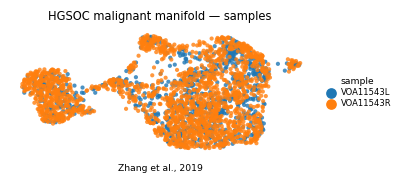

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('HGSOC malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Zhang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])